# Figure 3 starter: MSGD and damped Newton

A single hidden-layer classifier on 10 × 10 MNIST and CIFAR-10 images. **Start with MSGD.** Add damped Newton in the settings when ready. The reusable implementation is in `src/`; this notebook only selects and runs experiments.

Dauphin et al., [Figure 3 and Appendix F.1](https://arxiv.org/pdf/1406.2572v1): training classification error versus hidden units and epochs, plus the magnitude of the most negative Hessian eigenvalue. Cross entropy is our training loss; error means the percentage of wrongly classified training images.

In [ ]:
from src.pipelines.load.loader import DATA_DIR

ROOT = DATA_DIR.parent

In [ ]:
from torch.optim import SGD
from src.pipelines.mnist import run_mnist_pipeline
from src.pipelines.cifar import run_cifar_pipeline
from src.algorithms.damped_newton import DampedNewton
from src.models.neural_networks.mlp import build_mlp
from src.experiments.figure3 import load_training_data, train_model, plot_results

import json
import torch
import matplotlib.pyplot as plt

## Settings

These are **small starter settings**, not the paper's tuned configuration. Both datasets keep the existing [0, 1] pixel scaling; CIFAR keeps RGB channels. The model uses tanh, PyTorch's default linear-layer initialization, and CPU float64.

The paper shows widths 5, 25, and 50, and curves extending to 50 MNIST / 100 CIFAR epochs. It reports an 80-trial SGD hyperparameter search. We have not performed that search. Begin at width 5; add widths after checking the first run.

Curvature is exact for a **fixed probe of training examples**, not the whole original training set. The signed minimum eigenvalue is also retained in the results. MAX_PARAMETERS caps dense Hessian size; the starter limit is 2,000. Raise it deliberately for larger widths; memory grows quadratically and eigendecomposition cost cubically. Set `CURVATURE_SAMPLES = 0` for a wider MSGD-only sweep; exact damped Newton still requires a small model.

In [25]:
DATASETS = ("mnist", "cifar10")
METHODS = ("msgd", "damped_newton")  # Add "damped_newton" to compare both methods.
HIDDEN_UNITS = (5,)
EPOCHS = 100
TRAIN_LIMIT = 512  # None uses the complete prepared training split.
BATCH_SIZE = 32
CURVATURE_SAMPLES = 128
LEARNING_RATE = 0.05
MOMENTUM = 0.0
SEED = 42
MAX_PARAMETERS = 2000

## Load the prepared data

Existing exports are reused. If an export is missing, its existing preparation pipeline runs once. The first CIFAR run may therefore download and prepare CIFAR-10. Only the training split is used here. The selected examples stay fixed for comparisons. The existing 54,000/6,000 MNIST and 45,000/5,000 CIFAR training/validation splits are preserved; the held-out examples do not enter training or curvature measurements.

In [26]:
pipelines = {"mnist": run_mnist_pipeline, "cifar10": run_cifar_pipeline}
for name in DATASETS:
    if not (DATA_DIR / "processed" / name / "train.pt").exists():
        pipelines[name]()

training_data = {name: load_training_data(name, TRAIN_LIMIT) for name in DATASETS}
for name, data in training_data.items():
    print(name, len(data), "examples; image shape:", tuple(data.tensors[0].shape[1:]))

mnist 512 examples; image shape: (1, 10, 10)
cifar10 512 examples; image shape: (3, 10, 10)


## Train

For MSGD, `SGD` supplies the update and the DataLoader supplies minibatches. Every comparison restarts from the same seed and batch order. Measurements include epoch zero and the end of each epoch.

The optional damped Newton reference solves `(H + αI) step = -gradient` on each minibatch. It tries the paper's damping grid `1, 0.1, 0.01, 0.001, 0.0001, 0.00001`. Our explicit starter policy keeps only positive-definite shifts and accepts the candidate with the lowest improving loss on that same batch. Otherwise it leaves the parameters unchanged. This is a reference policy, not a claim to have recovered every detail of the original implementation.

In [27]:
results = []
for name, data in training_data.items():
    for hidden_units in HIDDEN_UNITS:
        for method in METHODS:
            torch.manual_seed(SEED)
            model = build_mlp(tuple(data.tensors[0].shape[1:]), hidden_units).double()
            if method == "msgd":
                optimizer = SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)
            elif method == "damped_newton":
                optimizer = DampedNewton(model, max_parameters=MAX_PARAMETERS)
            else:
                raise ValueError(f"Unknown method: {method}")
            print(f"{name} | {method} | {hidden_units} hidden units")
            history = train_model(
                model, data, optimizer, epochs=EPOCHS, batch_size=BATCH_SIZE,
                curvature_samples=CURVATURE_SAMPLES, seed=SEED, max_parameters=MAX_PARAMETERS,
            )
            results.append({
                "dataset": name, "method": method, "hidden_units": hidden_units,
                "training_examples": len(data), "history": history,
            })

mnist | msgd | 5 hidden units
Epoch 1: loss=2.3269, train error=87.11%
Epoch 2: loss=2.2987, train error=86.13%
Epoch 3: loss=2.2749, train error=85.94%
Epoch 4: loss=2.2532, train error=82.23%
Epoch 5: loss=2.2324, train error=78.12%
Epoch 6: loss=2.2115, train error=74.61%
Epoch 7: loss=2.1900, train error=70.31%
Epoch 8: loss=2.1678, train error=66.60%
Epoch 9: loss=2.1443, train error=61.52%
Epoch 10: loss=2.1193, train error=59.38%
Epoch 11: loss=2.0929, train error=57.23%
Epoch 12: loss=2.0650, train error=54.88%
Epoch 13: loss=2.0359, train error=52.93%
Epoch 14: loss=2.0054, train error=51.37%
Epoch 15: loss=1.9743, train error=50.39%
Epoch 16: loss=1.9422, train error=47.66%
Epoch 17: loss=1.9093, train error=49.61%
Epoch 18: loss=1.8763, train error=47.46%
Epoch 19: loss=1.8432, train error=47.27%
Epoch 20: loss=1.8101, train error=46.09%
Epoch 21: loss=1.7771, train error=45.12%
Epoch 22: loss=1.7443, train error=44.34%
Epoch 23: loss=1.7120, train error=44.34%
Epoch 24: los

KeyboardInterrupt: 

## Plot and save

Each dataset gets three panels. The left panel shows the smallest observed training error for each width. With one configured width it contains one point per method. Epoch curves use the largest configured width. Curves are single-seed results, not the paper's optimal curves. Zero values are omitted on logarithmic axes.

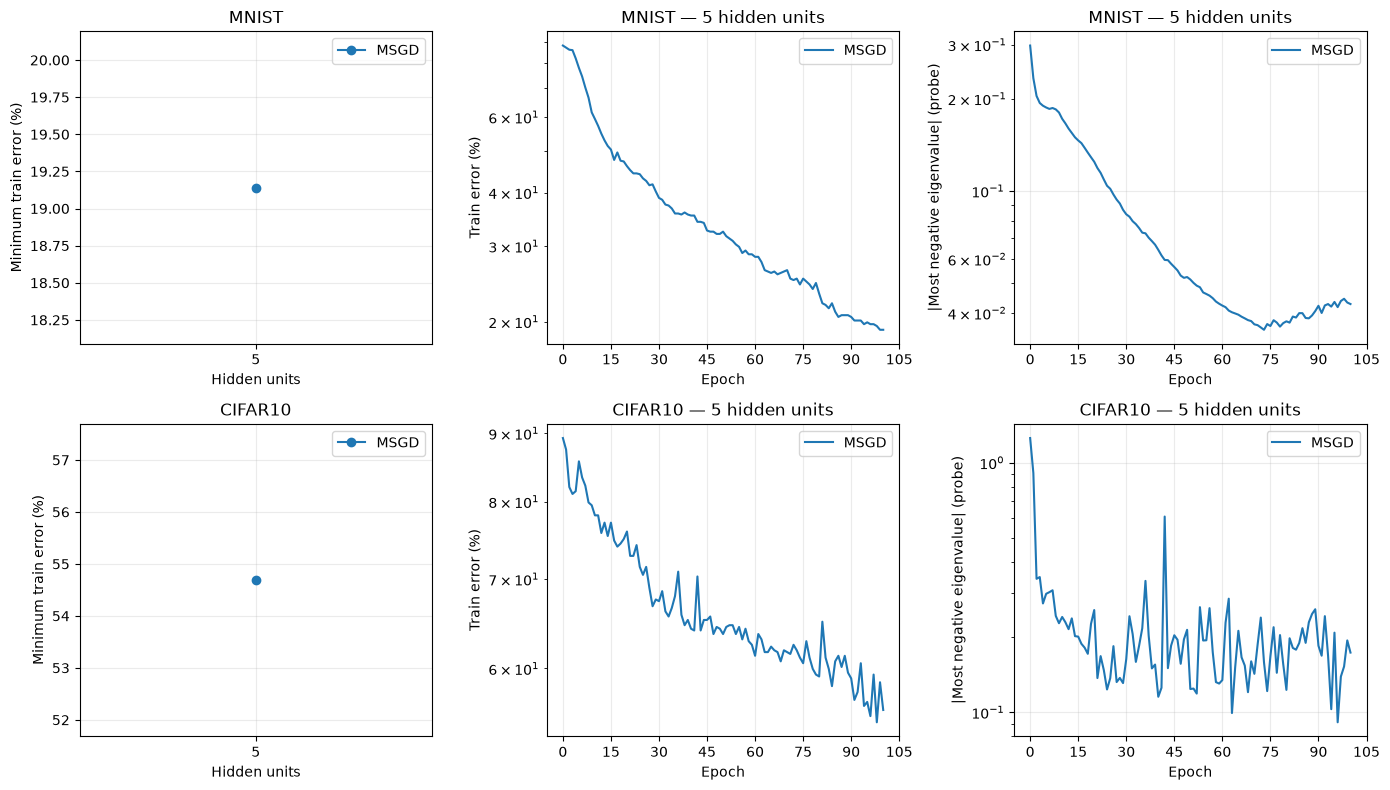

Saved: /Users/ken/Desktop/self-repositories/dauphin-sfn/results/figure3_starter


In [ ]:
output_dir = ROOT / "results" / "figure3_starter"
output_dir.mkdir(parents=True, exist_ok=True)
figure = plot_results(results)
figure.savefig(output_dir / "figure3.png", dpi=150, bbox_inches="tight")
record = {
    "settings": {
        "datasets": DATASETS, "methods": METHODS, "hidden_units": HIDDEN_UNITS,
        "epochs": EPOCHS, "train_limit": TRAIN_LIMIT, "batch_size": BATCH_SIZE,
        "curvature_samples": CURVATURE_SAMPLES, "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM, "seed": SEED, "dtype": "float64", "device": "cpu",
        "torch_version": str(torch.__version__), "max_parameters": MAX_PARAMETERS,
    },
    "runs": results,
}
(output_dir / "runs.json").write_text(json.dumps(record, indent=2, allow_nan=False))
plt.show()
print("Saved:", output_dir)